# Hilbert Sorting, `SnapIndex`, and `GeoKDTree`

`scgraph` supports two spatial indexes with the same query API:
- **`SnapIndex`**: reads coordinates in place; expects spatially ordered nodes (for example, via a Hilbert curve).
- **`GeoKDTree`** (`geokdtree`): 3D spherical KD-tree; builds its own tree from points in any order.


In [1]:
# Optional for plotting: !pip install folium matplotlib
import math
import random
import time

import folium
import matplotlib.pyplot as plt
from geokdtree import GeoKDTree

from scgraph import GeoGraph
from scgraph.helpers.hilbert import hilbert_order
from scgraph.utils import haversine, has_cpp

try:
    from scgraph.cpp import NodeOrderError, SnapIndex
except ImportError:
    from scgraph.helpers.snap_index import NodeOrderError, SnapIndex

print(f"C++ backend: {has_cpp()}")


C++ backend: True


## 1. Hilbert Curve Over 1,000 Points

`hilbert_order(points)` orders `(latitude, longitude)` pairs along a 2D space-filling curve so nearby coordinates stay close in memory.


In [2]:
rng = random.Random(42)
points = [
    [math.degrees(math.asin(2 * rng.random() - 1)), rng.uniform(-180, 180)]
    for _ in range(1000)
]

order = hilbert_order(points)
ordered_points = [points[i] for i in order]
hilbert_km = sum(haversine(a, b) for a, b in zip(ordered_points, ordered_points[1:]))
print(f"Hilbert path across 1,000 points: {hilbert_km:,.0f} km")

m = folium.Map(location=[0, 0], zoom_start=2)
folium.PolyLine(ordered_points, color="#1f77b4", weight=1.8, opacity=0.85).add_to(m)
m


Hilbert path across 1,000 points: 728,888 km


## 2. Building `GeoKDTree` and `SnapIndex`

Both indexes project `(latitude, longitude)` onto the 3D unit sphere `(x, y, z)`, avoiding polar distortion and `±180°` wrapping issues of a naive 2D KD-tree.
`GeoKDTree` accepts points in any order, whereas `SnapIndex` raises `NodeOrderError` until points are spatially ordered.


In [3]:
kdtree_raw = GeoKDTree(points)

try:
    SnapIndex(points)
except NodeOrderError as err:
    print("Unordered SnapIndex -> NodeOrderError:")
    print(" ", str(err).split(".")[0])

snap = SnapIndex(ordered_points)
kdtree = GeoKDTree(ordered_points)
print("Ordered SnapIndex & GeoKDTree -> OK")


Unordered SnapIndex -> NodeOrderError:
  nodes scattered in the order given: a query would scan about 29 blocks of 32 nodes (at most 16)
Ordered SnapIndex & GeoKDTree -> OK


## 3. Equivalence

Both indexes implement `closest_idx(point)` and `closest_idx_per_quadrant(point)` and return the exact same nodes across the globe (using `order[idx]` to map back to original indices).


In [4]:
queries = [
    [math.degrees(math.asin(2 * rng.random() - 1)), rng.uniform(-180, 180)]
    for _ in range(500)
] + [[90.0, 0.0], [-90.0, 0.0], [0.0, 180.0], [0.0, -180.0], [48.85, 2.35]]

closest_matches = sum(
    order[snap.closest_idx(q)] == kdtree_raw.closest_idx(q) for q in queries
)
quad_matches = sum(
    {d: (order[i] if i is not None else None) for d, i in snap.closest_idx_per_quadrant(q).items()}
    == kdtree_raw.closest_idx_per_quadrant(q)
    for q in queries
)
print(f"closest_idx matches             : {closest_matches}/{len(queries)}")
print(f"closest_idx_per_quadrant matches: {quad_matches}/{len(queries)}")

# Example right across the ±180° antimeridian (SE wraps to -178.1°)
q_antimeridian = [0.0, 179.5]
print("Antimeridian [0.0, 179.5]:")
print("  SnapIndex:", snap.closest_idx_per_quadrant(q_antimeridian))
print("  GeoKDTree:", kdtree.closest_idx_per_quadrant(q_antimeridian))


closest_idx matches             : 505/505
closest_idx_per_quadrant matches: 505/505
Antimeridian [0.0, 179.5]:
  SnapIndex: {'ne': 739, 'nw': 744, 'se': 235, 'sw': 746}
  GeoKDTree: {'ne': 739, 'nw': 744, 'se': 235, 'sw': 746}


### Why Quadrant Snapping Matters (`node_addition_type="quadrant"`)

Snapping only to the single nearest node (`"closest"`) can trap a route on the wrong side of a barrier (river, coast, opposite highway lane) and force a detour.
`closest_idx_per_quadrant` connects the origin or destination to up to **4 surrounding entry nodes** (`ne`, `nw`, `se`, `sw`), letting the router leave in the right direction—with identical results from `SnapIndex` and `GeoKDTree`:


In [5]:
# Origin [0, 0] going East to [0, 5.02]:
# Node 0 (NW) is closest overall (2.5 km) but only connects via a bridge far West (Node 1).
# Node 2 (NE) is slightly further (10.5 km) on the direct corridor East to Node 3.
nodes = [[0.01, -0.02], [0.0, -5.0], [0.05, 0.08], [0.0, 5.0]]
graph = [{} for _ in nodes]
for u, v in [(0, 1), (1, 3), (2, 3)]:
    graph[u][v] = graph[v][u] = haversine(nodes[u], nodes[v])

geo = GeoGraph(graph=graph, nodes=nodes)
origin = {"latitude": 0.0, "longitude": 0.0}
dest = {"latitude": 0.0, "longitude": 5.02}

res_closest = geo.get_shortest_path(origin, dest, node_addition_type="closest")
res_quad_snap = geo.get_shortest_path(origin, dest, node_addition_type="quadrant")

geo.snap_index = geo.geokdtree
res_quad_kd = geo.get_shortest_path(origin, dest, node_addition_type="quadrant")

assert res_quad_snap == res_quad_kd
print(f"closest              : {res_closest['length']:7,.1f} km  {res_closest['coordinate_path']}")
print(f"quadrant (SnapIndex) : {res_quad_snap['length']:7,.1f} km  {res_quad_snap['coordinate_path']}")
print(f"quadrant (GeoKDTree) : {res_quad_kd['length']:7,.1f} km  (exact match: True)")


closest              : 1,670.4 km  [[0.0, 0.0], [0.01, -0.02], [0.0, -5.0], [0.0, 5.0], [0.0, 5.02]]
quadrant (SnapIndex) :   559.8 km  [[0.0, 0.0], [0.05, 0.08], [0.0, 5.0], [0.0, 5.02]]
quadrant (GeoKDTree) :   559.8 km  (exact match: True)


## 4. High Latitudes and Antimeridian Performance

In `closest_idx_per_quadrant` (`node_addition_type="quadrant"`), empty quadrants and `±180°` boundaries separate the two indexes:
- **`GeoKDTree`** only splits `(x, y, z)` planes. A plane of its tree does not say whether a subtree lies east or west of the point, so it visits many subtrees when a quadrant is empty or crosses `±180°`.
- **`SnapIndex`**, in its C++ build, decides a quadrant on the unit vectors themselves: a node `p` is north of the point `q` if `p.z >= q.z`, and east if `q.x * p.y - q.y * p.x >= 0`. It applies the same two tests to the boxes of its tree, and skips a box that cannot hold a node of the quadrant, on either side of `±180°`.

Below is a simple 100,000-point dataset covering continental latitudes (`[-55°, 72°]`, longitudes `[-130°, 145°]` excluding the mid-Atlantic):

In [6]:
rng_b = random.Random(42)
land_points = []
while len(land_points) < 100_000:
    lat = rng_b.uniform(-55, 72)
    lon = rng_b.uniform(-130, 145)
    if -35 < lon < -15:
        continue
    land_points.append([lat, lon])

land_ordered = [land_points[i] for i in hilbert_order(land_points)]

t0 = time.perf_counter()
snap_100k = SnapIndex(land_ordered)
snap_build_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
kd_100k = GeoKDTree(land_ordered)
kd_build_ms = (time.perf_counter() - t0) * 1000
print(f"Build (100k): SnapIndex {snap_build_ms:.1f} ms | GeoKDTree {kd_build_ms:.1f} ms ({kd_build_ms / snap_build_ms:.1f}x slower)")


def avg_us(index, qs, method, repeat=5):
    fn = getattr(index, method)
    for q in qs[:10]:
        fn(q)
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        for q in qs:
            fn(q)
        best = min(best, (time.perf_counter() - t0) * 1e6 / len(qs))
    return best


zones = {
    "Europe\n(45–52°N)": [[rng_b.uniform(45, 52), rng_b.uniform(0, 10)] for _ in range(200)],
    "Arctic\n(78–88°N)": [[rng_b.uniform(78, 88), rng_b.uniform(-180, 180)] for _ in range(200)],
    "Antarctic\n(78–88°S)": [[rng_b.uniform(-88, -78), rng_b.uniform(-180, 180)] for _ in range(200)],
    "Antimeridian\n(±175–180°)": [[rng_b.uniform(-20, 20), rng_b.choice([-1, 1]) * rng_b.uniform(175, 180)] for _ in range(200)],
}

results = []
for name, qs in zones.items():
    sc, kc = avg_us(snap_100k, qs, "closest_idx"), avg_us(kd_100k, qs, "closest_idx")
    sq, kq = avg_us(snap_100k, qs, "closest_idx_per_quadrant"), avg_us(kd_100k, qs, "closest_idx_per_quadrant")
    results.append((name, sq, kq))
    print(f"{name.replace(chr(10), ' '):26s} | closest: {sc:4.1f} vs {kc:4.1f} us | quadrant: Snap {sq:5.1f} us, KD {kq:6.1f} us ({kq / sq:4.1f}x)")


Build (100k): SnapIndex 16.1 ms | GeoKDTree 72.8 ms (4.5x slower)
Europe (45–52°N)           | closest:  0.4 vs  0.4 us | quadrant: Snap   1.1 us, KD    1.6 us ( 1.4x)
Arctic (78–88°N)           | closest:  0.6 vs  2.8 us | quadrant: Snap   2.3 us, KD   18.8 us ( 8.2x)
Antarctic (78–88°S)        | closest:  0.9 vs  2.2 us | quadrant: Snap   2.6 us, KD   88.9 us (34.3x)


Antimeridian (±175–180°)   | closest:  0.5 vs  1.5 us | quadrant: Snap   3.4 us, KD  137.3 us (40.5x)


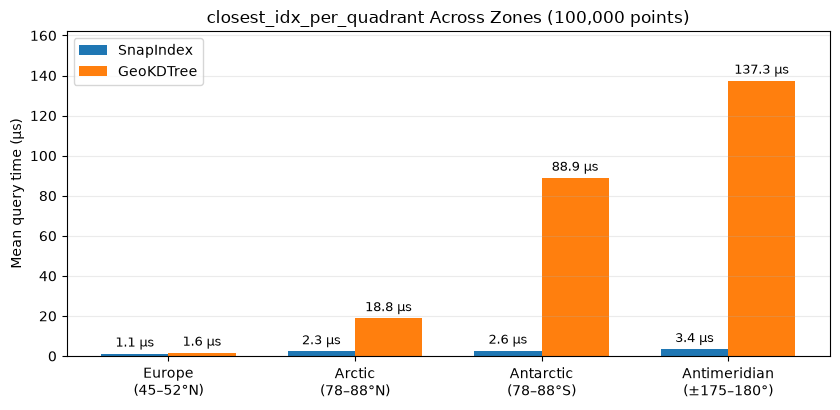

In [7]:
labels = [r[0] for r in results]
snap_us = [r[1] for r in results]
kd_us = [r[2] for r in results]
x = range(len(labels))
w = 0.36

fig, ax = plt.subplots(figsize=(8.5, 4.2))
b1 = ax.bar([i - w / 2 for i in x], snap_us, w, label="SnapIndex", color="#1f77b4")
b2 = ax.bar([i + w / 2 for i in x], kd_us, w, label="GeoKDTree", color="#ff7f0e")
ax.bar_label(b1, fmt="%.1f µs", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.1f µs", padding=3, fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylabel("Mean query time (µs)")
ax.set_title("closest_idx_per_quadrant Across Zones (100,000 points)")
ax.set_ylim(0, max(kd_us) * 1.18)
ax.legend()
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### Summary

- **Mid-latitudes**: both indexes answer in about a microsecond: 0.4 µs each for the nearest node, and 1.1 µs against 1.6 µs per quadrant.
- **High latitudes & antimeridian**: `SnapIndex` stays fast, because its two quadrant tests rule out whole boxes of nodes. `GeoKDTree` slows down sharply when quadrants are empty or cross `±180°`: per quadrant, it is about 8 to 40 times slower here.
- **Build**: `SnapIndex` builds about four times faster, directly on Hilbert-ordered coordinates.